In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [3]:
import warnings
sns.set(style = "whitegrid")
warnings.filterwarnings("ignore")

In [ ]:
train = pd.read_csv("train.csv")


In [ ]:
## Test csv data creates issues with parsing, so it need to be handeled manually. Judging by the error message (function read more fields in some of the records), the problem is that some of the fields contain commas and semicolons, which are not properly escaped.

    cols = ['id', 'seller_id', 'title', 'description', 'declared_category', 
            'brand', 'condition', 'price_pln', 'shipping_weight_kg', 'pack_size']
    rows, bad = [], []
    
    with open(path, encoding='utf-8') as f:
        lines = f.read().splitlines()[1:]
        
    for i, raw in enumerate(lines, start=2):
        line = raw.rstrip(';')
        if line.startswith('"') and line.endswith('"'):
            line = line[1:-1]
            
        parts = line.rsplit(',', 6)
        if len(parts) != 7:
            bad.append(i)
            continue
            
        head, *tail = parts
        hparts = head.split(',', 3)
        
        if len(hparts) < 3:
            bad.append(i)
            continue
            
        id_, seller, title = hparts[:3]
        desc = hparts[3].replace('""', '"').strip('"') if len(hparts) == 4 else ''
        
        rows.append([id_, seller, title.strip('"'), desc, *tail])
        
    if bad:
        warnings.warn(f"Skipped {len(bad)} unrecoverable lines. First 5: {bad[:5]}")
        
    df = pd.DataFrame(rows, columns=cols)
    num_cols = ['price_pln', 'shipping_weight_kg', 'pack_size']
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')
    
    return df

In [17]:
test = read_test_csv("test.csv")

In [18]:
test.head()

,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size
0,OFR_257241802,SEL_4980850,Tenso B320: standard canine play object (pack ...,Variant: standard. Also includes 1 pcs of free...,pets,Tenso,new,27.55,0.226,1.0
1,OFR_374432657,SEL_505005,Noro adjustable screen mount /standard / 1-pack,Monitor arm by Noro. Variant: standard. Sold a...,computers,Noro,used,122.07,2.452,1.0
2,OFR_779902838,SEL_6899503,MIRA F319: LARGE PROTEIN MIXING BOTTLE (...,Included main items: 1. Gym shaker by Mira. Va...,kitchen,Mira,new,48.00,0.247,1.0
3,OFR_633003662,SEL_7547871,recording mic support — 1 units — Velto C590,Bundle quantity: 1 units. Microphone stand by ...,music,Velto,new,35.27,2.171,1.0
4,OFR_236006399,SEL_561166,hanging wild bird dispenser — pack of one — Ve...,Pack of one main items. Bird feeder by Velto. ...,kitchen,,new,49.67,0.464,1.0


In [19]:
train.head()

,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size,target
0,OFR_191714271,SEL_7523257,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mi...,audio,Mira,used,70.43,5.233,1.0,1
1,OFR_517640949,SEL_2053194,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro....,computers,Noro,used,28.95,0.119,2.0,1
2,OFR_634805877,SEL_8620752,Tenso digital food balance / standard / quanti...,Included main items: 1. Kitchen scale by Tenso...,kitchen,Tenso,new,62.05,0.412,1.0,0
3,OFR_643990737,SEL_8396386,litter scoop — five main items — Velo ...,Cat tray cleaning shovel by Velto. Variant: st...,pets,Velto,used,102.26,0.499,5.0,0
4,OFR_260742748,SEL_5029882,LAPTOP SLEEVE — PACK OF FIVE — ASTER F219,Variant: standard. Also includes 3 pcs of free...,computers,Aster,used,144.84,0.856,5.0,0


In [28]:
train.shape

(16000, 11)

In [29]:
test.shape

(10000, 10)

In [21]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  16000 non-null  object 
 1   seller_id           16000 non-null  object 
 2   title               15530 non-null  object 
 3   description         15320 non-null  object 
 4   declared_category   15626 non-null  object 
 5   brand               15053 non-null  object 
 6   condition           16000 non-null  object 
 7   price_pln           15377 non-null  float64
 8   shipping_weight_kg  15038 non-null  float64
 9   pack_size           15515 non-null  float64
 10  target              16000 non-null  int64  
dtypes: float64(3), int64(1), object(7)
memory usage: 1.3+ MB


In [20]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  10000 non-null  object 
 1   seller_id           10000 non-null  object 
 2   title               10000 non-null  object 
 3   description         10000 non-null  object 
 4   declared_category   10000 non-null  object 
 5   brand               10000 non-null  object 
 6   condition           10000 non-null  object 
 7   price_pln           9607 non-null   float64
 8   shipping_weight_kg  9415 non-null   float64
 9   pack_size           9673 non-null   float64
dtypes: float64(3), object(7)
memory usage: 781.4+ KB


In [38]:
train.isnull().sum().sort_values(ascending=False)

shipping_weight_kg    962
brand                 947
description           680
price_pln             623
pack_size             485
title                 470
declared_category     374
seller_id               0
id                      0
condition               0
target                  0
dtype: int64

In [62]:
print(test["declared_category"].value_counts())
print(test["brand"].value_counts())

print("Number of unique sellers in test dataset: ", test["seller_id"].nunique())


declared_category
computers    1640
audio        1542
kitchen      1473
sport        1197
books        1094
beauty        977
garden        786
pets          580
music         459
              252
Name: count, dtype: int64
brand
Tenso    1903
Noro     1888
Aster    1879
Mira     1877
Velto    1847
          606
Name: count, dtype: int64
Number of unique sellers in test dataset:  500


In [23]:
train["target"].value_counts()

target
0    13279
1     2721
Name: count, dtype: int64

In [33]:
#percent of corrupted data in train dataset
train["target"].value_counts()[1] / train.shape[0] * 100

np.float64(17.00625)

<Axes: title={'center': 'Corruption Rate by Declared Category'}, xlabel='Declared Category'>

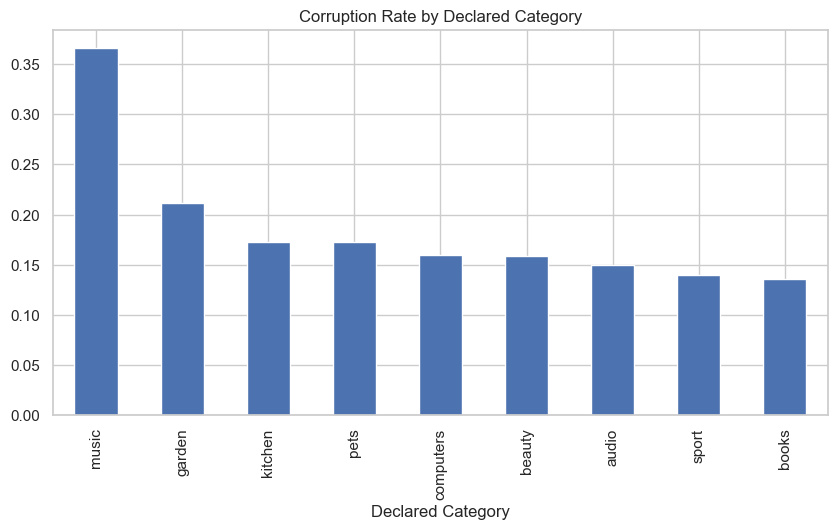

In [ ]:
#declared category has the lowest amount of missing values
corruption_by_category = train.groupby("declared_category")["target"].mean().sort_values(ascending=False)
corruption_by_category.plot(kind='bar', figsize=(10, 5), title='Corruption Rate by Declared Category', xlabel='Declared Category')

# music category has the highest corruption rate, while books category has the lowest corruption rate. The declared category may be a useful feature.
# we cannot exlude the possibility that the declared category is wrongly assigned 


<Axes: title={'center': 'Controlled data corruption in music category'}, xlabel='target'>

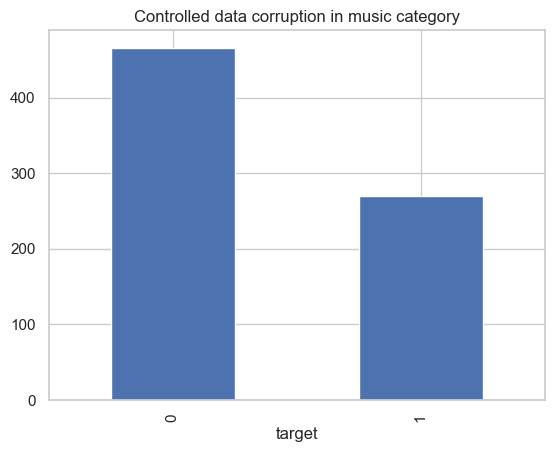

In [50]:
train[train["declared_category"] == "music"].value_counts("target").plot(kind = 'bar', title = "Controlled data corruption in music category")

In [117]:
train.head()

,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size,target,text_pack,price_q
0,OFR_191714271,SEL_7523257,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mi...,audio,Mira,used,70.43,5.233,1.0,1,NaN,Q2
1,OFR_517640949,SEL_2053194,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro....,computers,Noro,used,28.95,0.119,2.0,1,NaN,Q1
2,OFR_634805877,SEL_8620752,Tenso digital food balance / standard / quanti...,Included main items: 1. Kitchen scale by Tenso...,kitchen,Tenso,new,62.05,0.412,1.0,0,NaN,Q2
3,OFR_643990737,SEL_8396386,litter scoop — five main items — Velo ...,Cat tray cleaning shovel by Velto. Variant: st...,pets,Velto,used,102.26,0.499,5.0,0,NaN,Q3
4,OFR_260742748,SEL_5029882,LAPTOP SLEEVE — PACK OF FIVE — ASTER F219,Variant: standard. Also includes 3 pcs of free...,computers,Aster,used,144.84,0.856,5.0,0,3.0,Q3


Text(0.5, 1.0, 'Correlation Matrix')

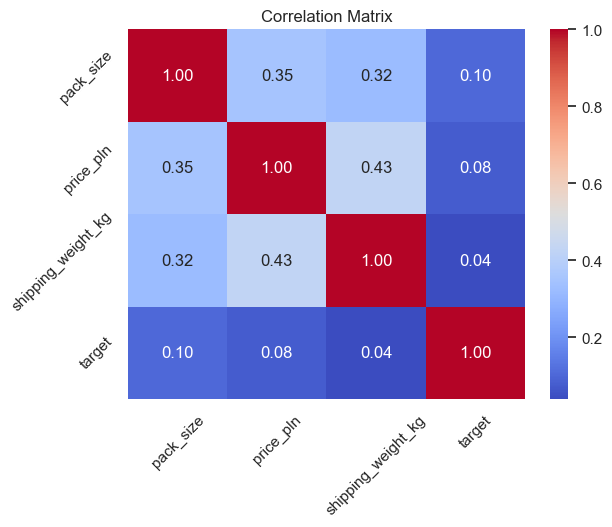

In [ ]:
corr = train[[ "pack_size", "price_pln", "shipping_weight_kg", "target"]].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.title("Correlation Matrix")
# no strong correlation between features and target, 
#pack size has the highest correlation with target variable, but it is still weak (0.10)

Text(0.5, 1.0, 'Pack Size Distribution')

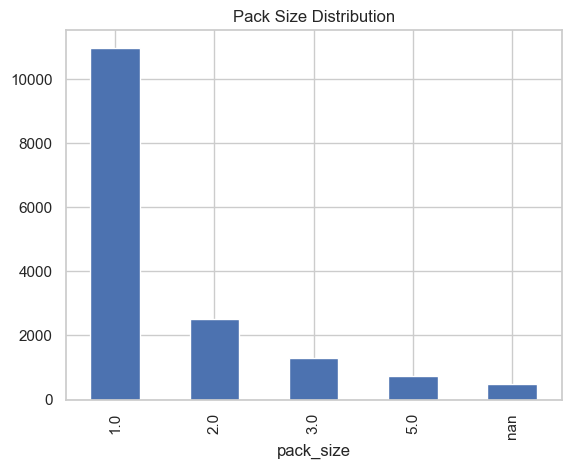

In [86]:
train.pack_size.value_counts(dropna=False).sort_index().plot(kind='bar')
plt.title('Pack Size Distribution')

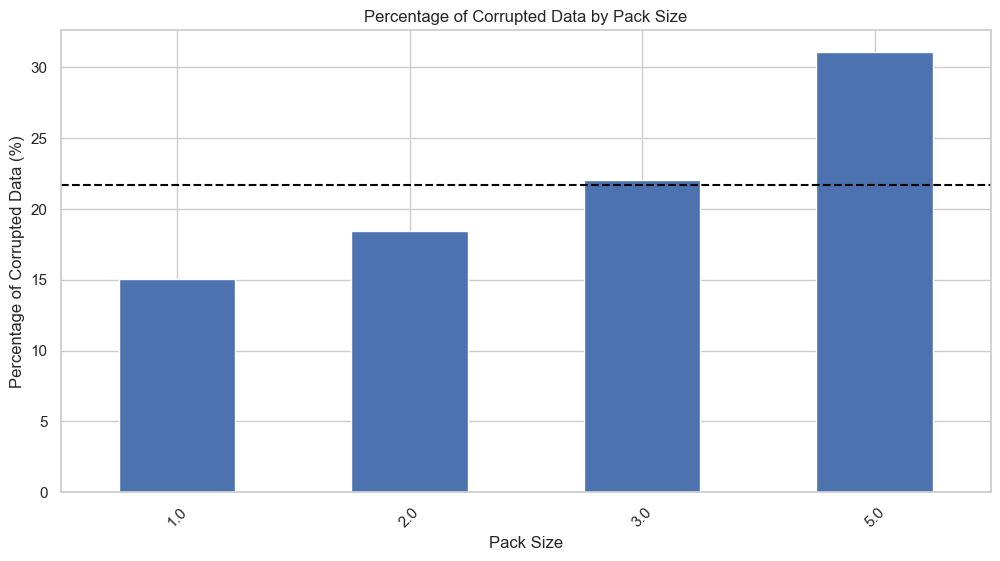

In [ ]:
# evaluatinf the relationship between pack_size and target variable

percent = train.groupby('pack_size')['target'].mean() * 100

percent = percent.sort_values(ascending=True)

percent.plot(kind='bar', figsize=(12, 6), )

text = (train.title.fillna('') + ' ' + train.description.fillna('')).str.lower()
train['text_pack'] = pd.to_numeric(text.str.extract(r'(\d+)\s*pcs', expand=False), errors='coerce')

plt.axhline(percent.mean(), ls='--', color='black', label='avg')


plt.title('Percentage of Corrupted Data by Pack Size')
plt.ylabel('Percentage of Corrupted Data (%)')
plt.xlabel('Pack Size')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# most of the pack sizes have a corruption rate below the average, but there are some pack sizes with a significantly higher corruption rate. This suggests that pack size may be a useful feature for predicting corruption in the data.
# however it can be explained by free accessories not included in the pack size

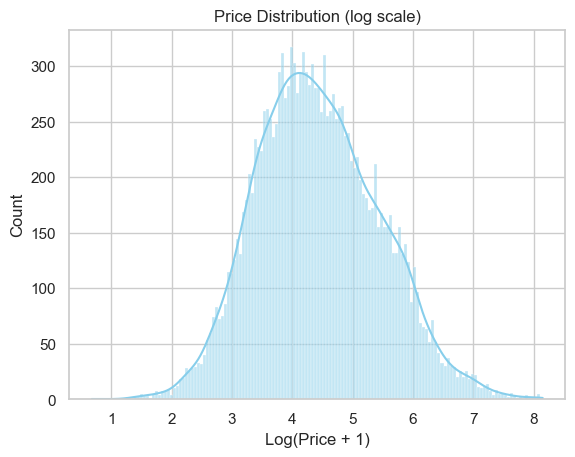

In [113]:
sns.histplot(np.log1p(train["price_pln"]), bins = 150, kde = True,  color = "skyblue")
plt.title("Price Distribution (log scale)")
plt.xlabel("Log(Price + 1)")
plt.show()

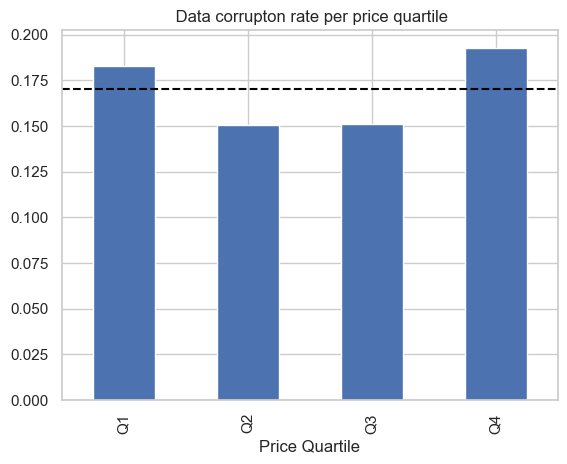

In [110]:
# Data corrupton rate per price quartile
train['price_q'] = pd.qcut(train.price_pln, 4, labels=['Q1','Q2','Q3','Q4'])
train.groupby('price_q', observed=True)['target'].mean().plot(kind='bar')
plt.title(' Data corrupton rate per price quartile')
plt.xlabel('Price Quartile')
plt.axhline(0.170, ls='--', color='black')

In [ ]:
print(train.groupby('seller_id').size().describe())
# std equals 0, meaning every seller has exactly 20 offers

count    800.0
mean      20.0
std        0.0
min       20.0
25%       20.0
50%       20.0
75%       20.0
max       20.0
dtype: float64


Sellers with no corrupted data: 31
Sellers with >=5 corrupted items: 207


Text(0.5, 1.0, 'Data Corruption Rate Distribution by Seller')

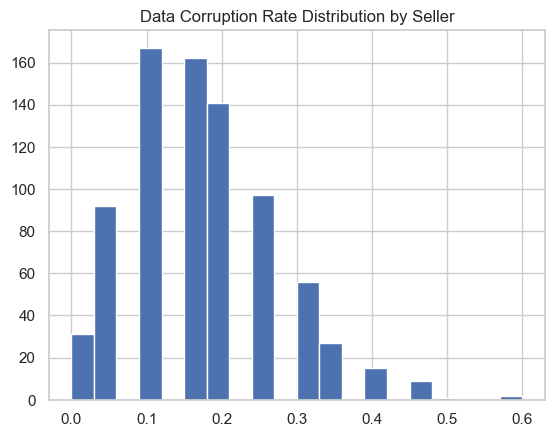

In [118]:
# Wskaźnik skażenia per sprzedawca
seller_stats = train.groupby('seller_id')['target'].agg(['mean','sum','count'])
seller_stats.columns = ['corrupt_rate','n_corrupt','n_offers']

print(f'Sellers with no corrupted data: {(seller_stats.n_corrupt == 0).sum()}')
print(f'Sellers with >=5 corrupted items: {(seller_stats.n_corrupt >= 5).sum()}')
seller_stats['corrupt_rate'].hist(bins=20)
plt.title('Data Corruption Rate Distribution by Seller')